# Deep Deterministic Policy Gradient (DDPG)

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import copy
import os
import random
from tqdm import tqdm
import collections
from torch.distributions import Normal
import gymnasium as gym

os.environ['KMP_DUPLICATE_LIB_OK']='True'

In [2]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = collections.deque(maxlen=capacity) 

    def add(self, state, action, reward, next_state, done): 
        self.buffer.append((state, action, reward, next_state, done)) 

    def sample(self, batch_size): 
        transitions = random.sample(self.buffer, batch_size)
        state, action, reward, next_state, done = zip(*transitions)
        return np.array(state), action, reward, np.array(next_state), done 

    def size(self): 
        return len(self.buffer)

# Reto 1
Crear las redes del actor y critico.
* Para el actor:
   * Capa de entrada lineal con numero de neuronas igual a la dimension de la capa oculta. Usar ReLU de funcion de activacion.
   * Capa de salida lineal con numero de neuronas igual a la dimension del espacio de acciones. Usar tangente hiperbolica como funcion de activacion.
* Para el critico:
   * Capa de entrada lineal con numero de neuronas igual a la dimension de la capa oculta. Usar ReLU de funcion de activacion.
   * Capa oculta lineal con numero de neuronas igual a hidden_dim y funcion de activacion ReLU.
   * Capa de salida lineal con solo una neurona.

In [3]:
class PolicyNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim, action_bound):
        super(PolicyNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, action_dim)
        self.action_bound = action_bound  # cota de accion es el valor de accion maximation que el ambiente puede aceptar

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return torch.tanh(self.fc2(x)) * self.action_bound


class QValueNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(QValueNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim + action_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, hidden_dim)
        self.fc_out = torch.nn.Linear(hidden_dim, 1)

    def forward(self, x, a):
        cat = torch.cat([x, a], dim=1) 
        x = F.relu(self.fc1(cat))
        x = F.relu(self.fc2(x))
        return self.fc_out(x)

# Reto 2
Crear red DDPG.
* Es un algoritmo off-policy.
* Utiliza bufer de experiencias.
* Utiliza ruido Gaussiano para exploracion.
* Es un algoritmo actor-critico que entrena una red para la politica y otro para la funcion de valor.

In [4]:
class DDPG:
    ''' DDPG algorithm '''
    def __init__(self, state_dim, hidden_dim, action_dim, action_bound, sigma, actor_lr, critic_lr, tau, gamma, device):
        self.actor = PolicyNet(state_dim, hidden_dim, action_dim, action_bound).to(device)
        self.critic = QValueNet(state_dim, hidden_dim, action_dim).to(device)
        self.target_actor = PolicyNet(state_dim, hidden_dim, action_dim, action_bound).to(device)
        self.target_critic = QValueNet(state_dim, hidden_dim, action_dim).to(device)
        # Inicializar el valor de la target value network con los mismos parametros de la value network
        self.target_critic.load_state_dict(self.critic.state_dict())
        # Inicializar el valor de la target policy network con los mismos parametros que la politica
        self.target_actor.load_state_dict(self.actor.state_dict())
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(), lr=actor_lr)
        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(), lr=critic_lr)
        self.gamma = gamma
        self.sigma = sigma  # Desviacion estandar y media del ruido Gaussiano
        self.tau = tau  # Parametro de actualizacion suave
        self.action_dim = action_dim
        self.device = device

    def take_action(self, state):
        state = torch.tensor([state], dtype=torch.float).to(self.device)
        action = self.actor(state).item()
        # Anadir ruido a la accion para motivar a exploracion
        action = action + self.sigma * np.random.randn(self.action_dim)
        return action

    def soft_update(self, net, target_net):
        for param_target, param in zip(target_net.parameters(), net.parameters()):
            param_target.data.copy_(param_target.data * (1.0 - self.tau) + param.data * self.tau)

    def update(self, transition_dict):
        states = torch.tensor(transition_dict['states'], dtype=torch.float).to(self.device)
        actions = torch.tensor(transition_dict['actions'], dtype=torch.float).view(-1, 1).to(self.device)
        rewards = torch.tensor(transition_dict['rewards'], dtype=torch.float).view(-1, 1).to(self.device)
        next_states = torch.tensor(transition_dict['next_states'], dtype=torch.float).to(self.device)
        dones = torch.tensor(transition_dict['dones'], dtype=torch.float).view(-1, 1).to(self.device)

        next_q_values = self.target_critic(next_states, self.target_actor(next_states).detach())
        q_targets = rewards + self.gamma * next_q_values * (1 - dones)
        critic_loss = F.mse_loss(self.critic(states, actions), q_targets.detach())
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        self.critic_optimizer.step()

        actor_loss = -torch.mean(self.critic(states, self.actor(states)))
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        self.soft_update(self.actor, self.target_actor)  # Actualizacion suave para el actor
        self.soft_update(self.critic, self.target_critic)  # Actualizacion suave para el critico

# Reto 3
Entrenar la red DDPG en el ambiente Pendulum.

In [5]:
actor_lr = 3e-4
critic_lr = 3e-3
num_episodes = 500
hidden_dim = 64
gamma = 0.98
tau = 0.005  # Parametro de actualizacion suave
buffer_size = 10000
minimal_size = 1000
batch_size = 64
sigma = 0.01  # Desviacion estandar del ruido Gaussiano
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

env_name = 'Pendulum-v1'
env = gym.make(env_name)
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
replay_buffer = ReplayBuffer(buffer_size)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]
action_bound = env.action_space.high[0]  # Valor maximo de accion
agent = DDPG(state_dim, hidden_dim, action_dim, action_bound, sigma, actor_lr, critic_lr, tau, gamma, device)

return_list = []
for i in range(10):
    with tqdm(total=int(num_episodes/10), desc='Iteracion %d' % i) as pbar:
        for i_episode in range(int(num_episodes/10)):
            episode_return = 0
            state, _ = env.reset(seed = 0)
            done = False
            while not done:
                action = agent.take_action(state)
                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated
                replay_buffer.add(state, action, reward, next_state, done)
                state = next_state
                episode_return += reward
                if replay_buffer.size() > minimal_size:
                    b_s, b_a, b_r, b_ns, b_d = replay_buffer.sample(batch_size)
                    transition_dict = {'states': b_s, 'actions': b_a, 'next_states': b_ns, 'rewards': b_r, 'dones': b_d}
                    agent.update(transition_dict)
            return_list.append(episode_return)
            if (i_episode+1) % 10 == 0:
                pbar.set_postfix({'Episodio': '%d' % (num_episodes/10 * i + i_episode+1), 'Retorno': '%.3f' % np.mean(return_list[-10:])})
            pbar.update(1)

C:\Users\e807575\AppData\Local\Temp\ipykernel_14856\3329635383.py:21: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\utils\tensor_new.cpp:281.)
  state = torch.tensor([state], dtype=torch.float).to(self.device)
Iteracion 9: 100%|█████████████████████████████████████| 50/50 [01:57<00:00,  2.36s/it, Episodio=500, Retorno=-131.395]


In [7]:
def moving_average(a, window_size):
    cumulative_sum = np.cumsum(np.insert(a, 0, 0)) 
    middle = (cumulative_sum[window_size:] - cumulative_sum[:-window_size]) / window_size
    r = np.arange(1, window_size-1, 2)
    begin = np.cumsum(a[:window_size-1])[::2] / r
    end = (np.cumsum(a[:-window_size:-1])[::2] / r)[::-1]
    return np.concatenate((begin, middle, end))

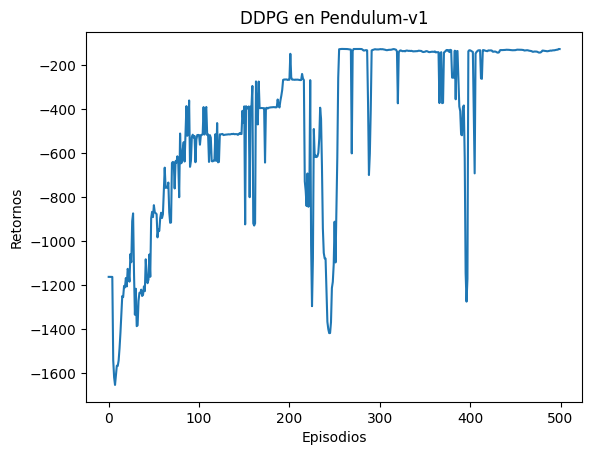

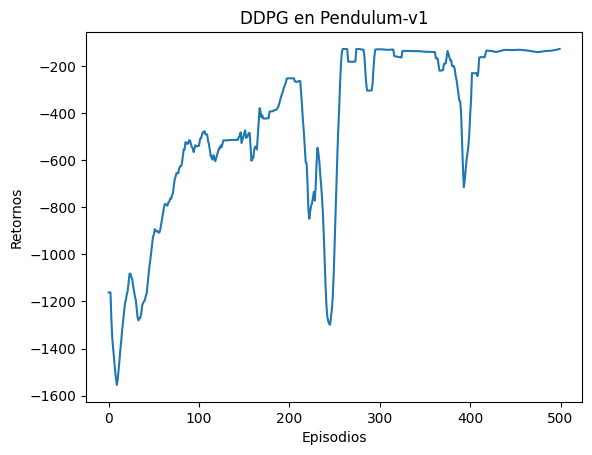

In [8]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('DDPG en {}'.format(env_name))
plt.show()

mv_return = moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('DDPG en {}'.format(env_name))
plt.show()

# Reto 4
Pruebe la red DDPG entrenada en el sistema Pendulum y vea lo resultados. 

In [9]:
#Obtener estado inicial
env = gym.make('Pendulum-v1', render_mode = 'human')
for _ in range(10):
    state, _ = env.reset()
    episode_return = 0
    for step in range(200):
        with torch.no_grad():  # No necesitamos calcular gradientes en evaluación
            action = agent.take_action(state)    
        #Obtener s', r', done e info
        state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        episode_return += reward
    
        if done:
            break
    print(f'Retorno obtenido {episode_return}')
# Cerrar el ambiente
env.close()

Retorno obtenido -1061.9609739473703
Retorno obtenido -129.77276905223997
Retorno obtenido -1267.572593327351
Retorno obtenido -714.6203224142425
Retorno obtenido -123.1602788404802
Retorno obtenido -6.5188723223772564
Retorno obtenido -130.50028630004041
Retorno obtenido -130.61468989309319
Retorno obtenido -1399.7691030787594
Retorno obtenido -132.7581444955013
